# Notebook 6 — Explainability

**SHAP** analysis on network and audio features.
Map SHAP values back to frequency-related audio features (MFCC, spectral centroid, chroma).


In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from sklearn.ensemble import RandomForestClassifier

from preprocessing import DataLoader, FeatureProcessor
from signal_generator import SignalGenerator
from audio_features import AudioFeatureExtractor
from evaluate import Evaluator

FIG_DIR = '../reports/figures'
SAMPLE_SIZE = 800
shap.initjs()


In [2]:
loader = DataLoader(data_dir='../data/raw')
train_df, test_df = loader.load_nsl_kdd(sample_size=SAMPLE_SIZE)

processor = FeatureProcessor()
X_train, y_train, feat_names = processor.prepare_features(train_df, fit=True)
X_test, y_test, _ = processor.prepare_features(test_df, fit=False)

sig_gen = SignalGenerator()
sig_gen.fit(X_train)
extractor = AudioFeatureExtractor()

train_signals = sig_gen.generate_batch(X_train)
test_signals = sig_gen.generate_batch(X_test)
X_train_audio = extractor.extract_batch_vectors(train_signals, n_jobs=4)
X_test_audio = extractor.extract_batch_vectors(test_signals, n_jobs=4)
audio_feat_names = extractor.get_feature_names(train_signals[0])

# Subsample for SHAP speed
shap_idx = np.random.choice(len(X_test), min(200, len(X_test)), replace=False)
X_shap_net = X_test[shap_idx]
X_shap_audio = X_test_audio[shap_idx]


C:\Users\kaavi\OneDrive\Desktop\Audio-Based-Network-Intrusion-Detection-System\venv\Lib\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=1024 is too large for input signal of length=690
  warnings.warn(


## SHAP: Original Network Features


<Figure size 1000x800 with 0 Axes>

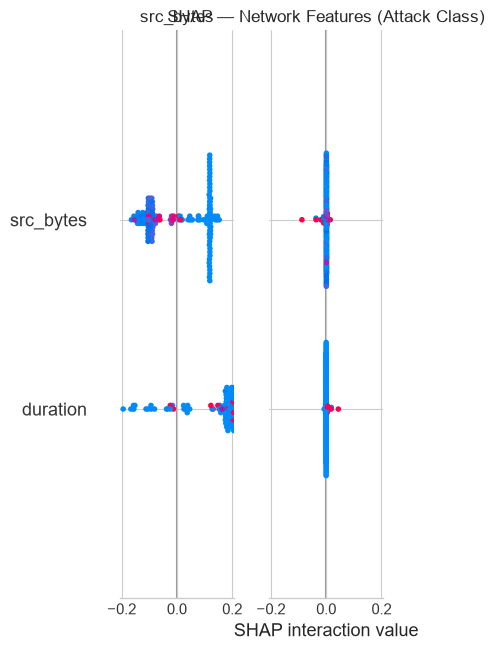

In [3]:
rf_net = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_net.fit(X_train, y_train)

explainer_net = shap.TreeExplainer(rf_net)
shap_values_net = explainer_net.shap_values(X_shap_net)
sv_net = shap_values_net[1] if isinstance(shap_values_net, list) else shap_values_net

plt.figure(figsize=(10, 8))
shap.summary_plot(sv_net, X_shap_net, feature_names=feat_names, show=False)
plt.title('SHAP — Network Features (Attack Class)')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/19_shap_network_beeswarm.png', dpi=300, bbox_inches='tight')
plt.show()


## SHAP: Audio-Derived Features


<Figure size 1000x800 with 0 Axes>

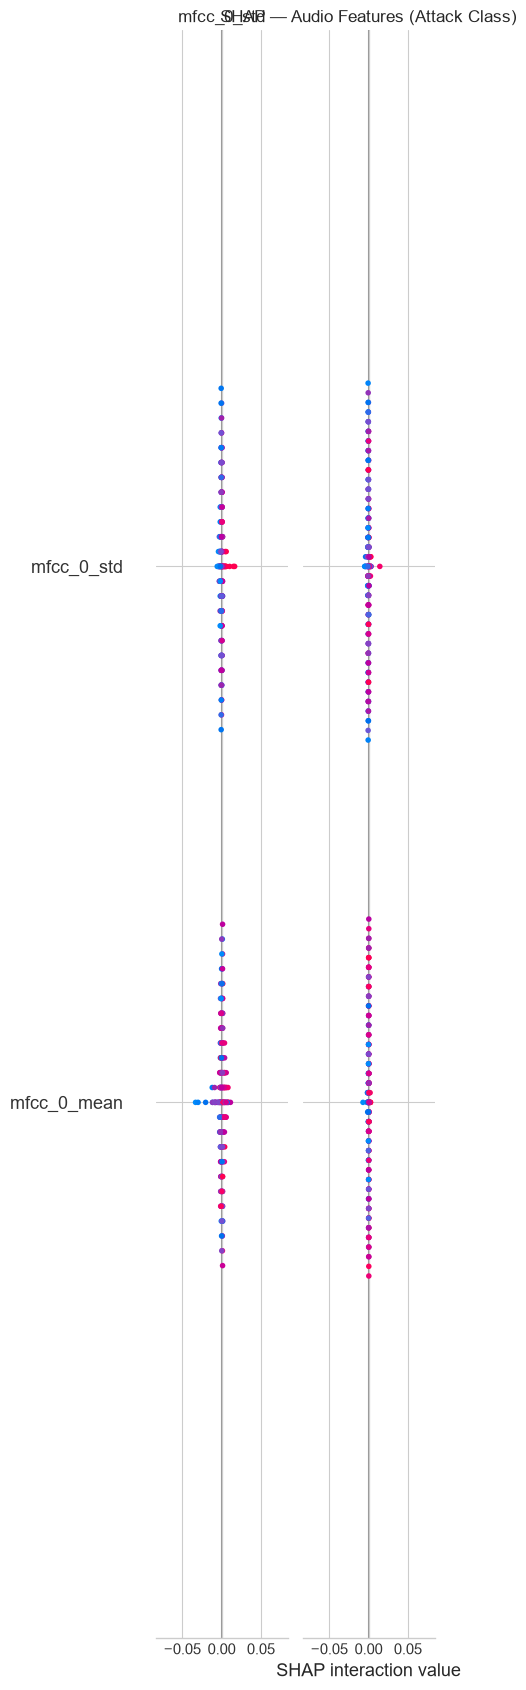

In [4]:
rf_audio = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_audio.fit(X_train_audio, y_train)

explainer_audio = shap.TreeExplainer(rf_audio)
shap_values_audio = explainer_audio.shap_values(X_shap_audio)
sv_audio = shap_values_audio[1] if isinstance(shap_values_audio, list) else shap_values_audio

plt.figure(figsize=(10, 8))
shap.summary_plot(sv_audio, X_shap_audio, feature_names=audio_feat_names, max_display=20, show=False)
plt.title('SHAP — Audio Features (Attack Class)')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/20_shap_audio_beeswarm.png', dpi=300, bbox_inches='tight')
plt.show()


## Which Frequencies Contribute Most to Attack Detection?

Map SHAP values back to frequency bands via MFCC and spectral centroid features.


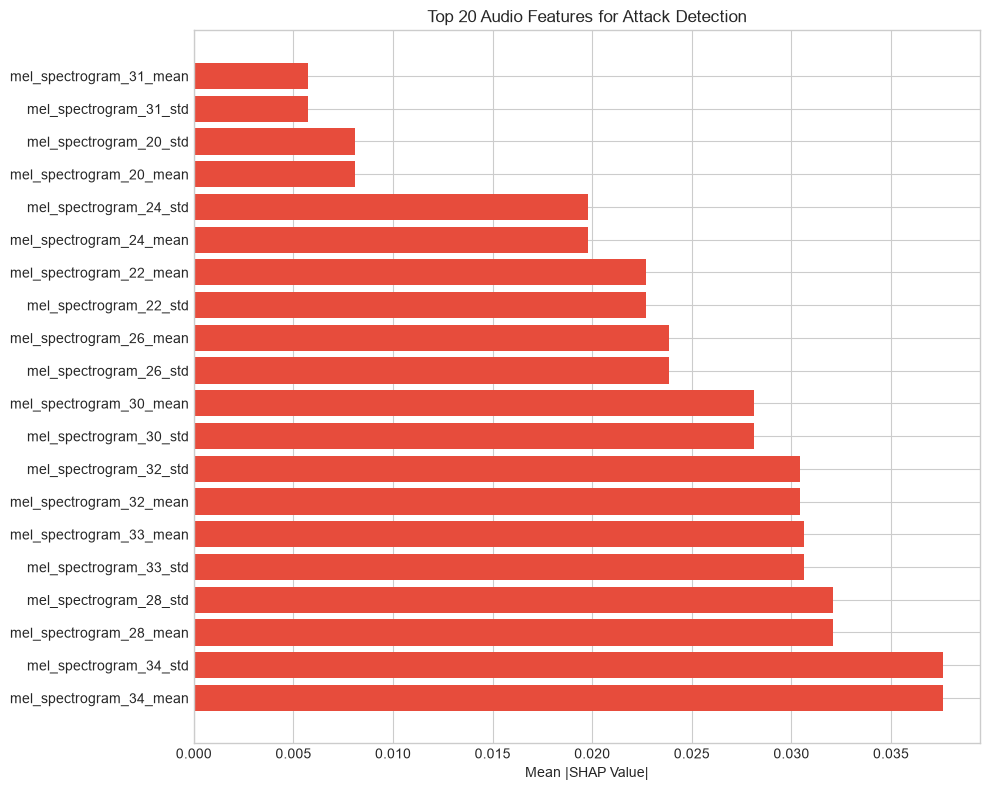

,feature,importance
37,mfcc_18_std,0.001296
36,mfcc_18_mean,0.001296
2,mfcc_1_mean,0.001206
3,mfcc_1_std,0.001206
23,mfcc_11_std,0.001197
22,mfcc_11_mean,0.001197
14,mfcc_7_mean,0.000824
15,mfcc_7_std,0.000824
38,mfcc_19_mean,0.000810
39,mfcc_19_std,0.000810


In [5]:
# Feature importance ranking
imp = np.abs(np.asarray(sv_audio)).mean(axis=0).ravel()
n = min(len(imp), len(audio_feat_names))
importance_audio = pd.DataFrame({
    'feature': audio_feat_names[:n],
    'importance': imp[:n]
}).sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
top20 = importance_audio.head(20)
ax.barh(top20['feature'], top20['importance'], color='#e74c3c')
ax.set_title('Top 20 Audio Features for Attack Detection')
ax.set_xlabel('Mean |SHAP Value|')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/21_frequency_importance.png', dpi=300, bbox_inches='tight')
plt.show()

# Frequency analysis
freq_features = importance_audio[importance_audio['feature'].str.contains('mfcc|centroid|chroma|spectral')]
display(freq_features.head(15))


## Benign vs Attack Spectrogram Gallery


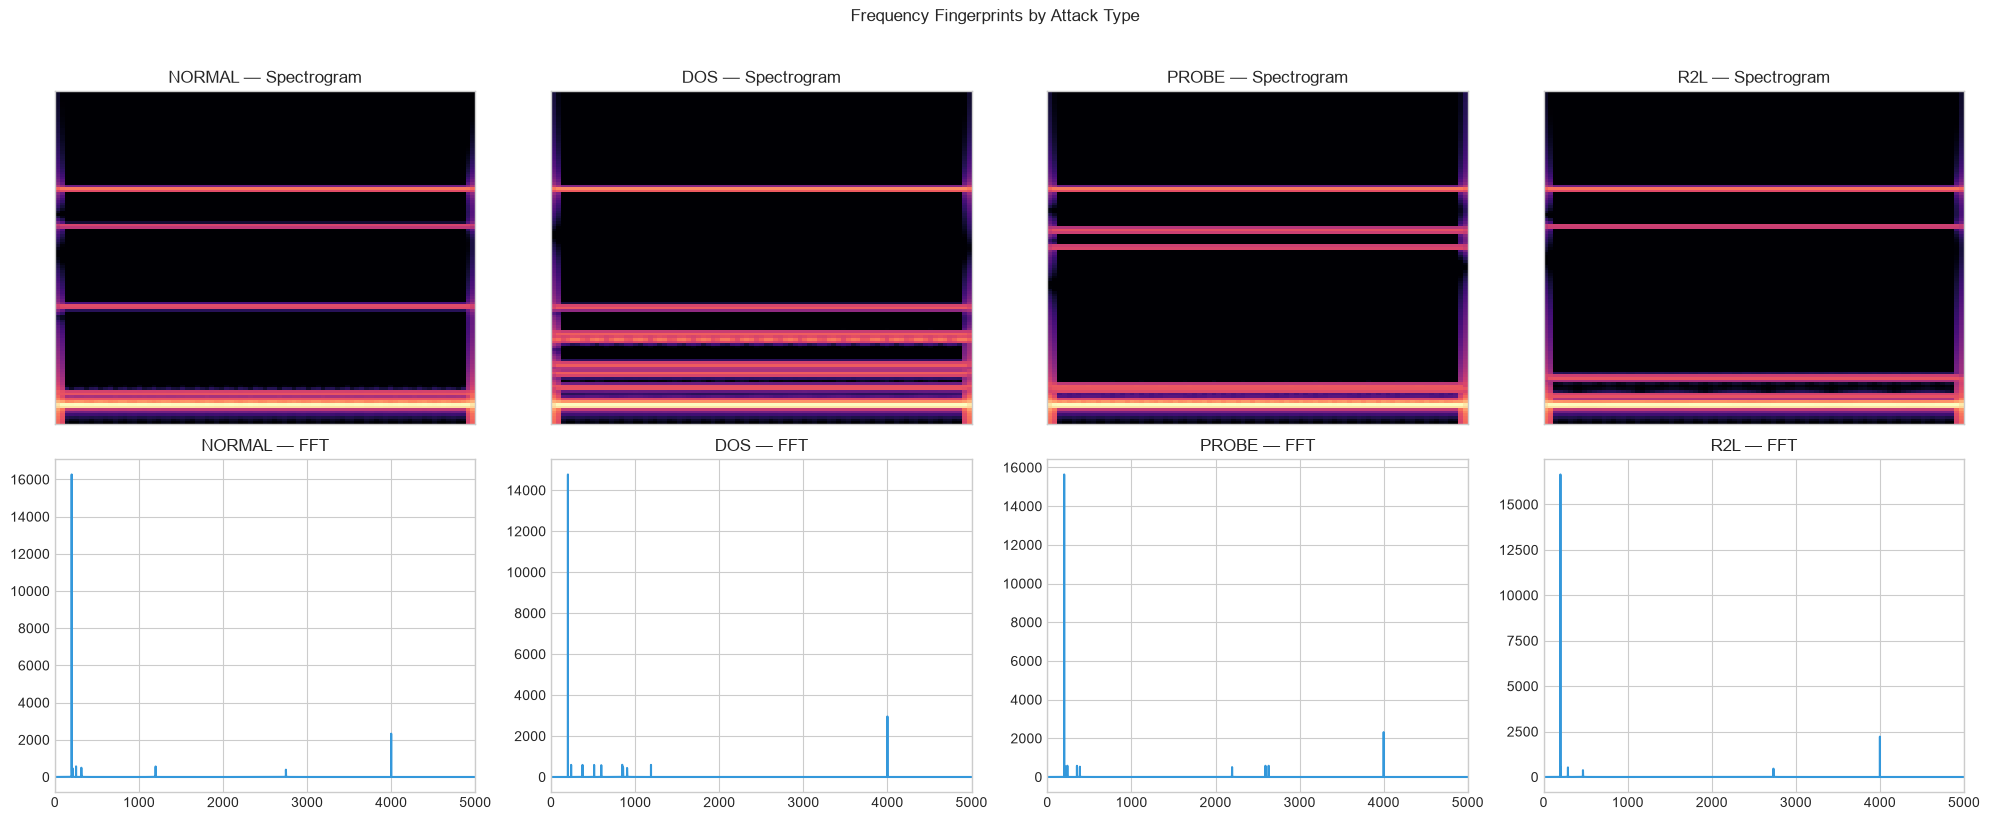

In [6]:
import librosa.display

attack_types = train_df.groupby('attack_category').head(1)
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
categories = ['normal', 'dos', 'probe', 'r2l']

for i, cat in enumerate(categories):
    mask = train_df['attack_category'].values == cat
    if not mask.any():
        continue
    row_idx = np.where(mask)[0][0]
    sig = train_signals[row_idx]
    mel = librosa.feature.melspectrogram(y=sig, sr=22050)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    librosa.display.specshow(mel_db, ax=axes[0, i], sr=22050, cmap='magma')
    axes[0, i].set_title(f'{cat.upper()} — Spectrogram')

    freqs, mag = sig_gen.compute_fft(sig)
    axes[1, i].plot(freqs, mag, color='#3498db')
    axes[1, i].set_title(f'{cat.upper()} — FFT')
    axes[1, i].set_xlim(0, 5000)

plt.suptitle('Frequency Fingerprints by Attack Type', y=1.02)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/22_spectrogram_gallery.png', dpi=300, bbox_inches='tight')
plt.show()


## Interactive Plotly Dashboard


In [7]:
# Interactive spectrogram
benign_sig = train_signals[y_train == 0][0]
attack_sig = train_signals[y_train == 1][0]

mel_b = librosa.feature.melspectrogram(y=benign_sig, sr=22050)
mel_a = librosa.feature.melspectrogram(y=attack_sig, sr=22050)

fig = make_subplots(rows=1, cols=2, subplot_titles=['Benign Spectrogram', 'Attack Spectrogram'])
fig.add_trace(go.Heatmap(z=librosa.power_to_db(mel_b), colorscale='Viridis'), row=1, col=1)
fig.add_trace(go.Heatmap(z=librosa.power_to_db(mel_a), colorscale='Viridis'), row=1, col=2)
fig.update_layout(title='Interactive Spectrogram Comparison', height=400)
fig.write_html(f'{FIG_DIR}/23_interactive_spectrogram.html')
fig.show()


## Summary

SHAP rankings on audio features highlight MFCC and spectral centroid coefficients as the strongest predictors. Comparing these against the network-feature SHAP plot shows which information survives the sonification step.

MFCC and spectral centroid features tend to rank highest in the audio SHAP plot.
